# Level 3 · Task 3 — Data Visualization
**Cognifyz Data Science Internship**

**Goals**
1. Visualize the distribution of ratings with several chart types.
2. Compare average ratings across cuisines and cities.
3. Visualize the relationship between features and the target (`Aggregate rating`).

**Conventions:** rating `0` means *Not rated*, so averages and relationships use **rated restaurants only**
(the distribution section shows both). Error bars are 95% confidence intervals of the mean. Rankings require a
minimum sample size so that tiny groups do not dominate.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("../dataset/Dataset.csv")
TARGET = "Aggregate rating"
TOP_N = 15
MIN_CITY_N = 20      # minimum rated restaurants for a city to enter "highest/lowest rated" rankings
LARGE_CITY_N = 100   # cities with at least this many rated restaurants count as "large"

COUNTRY_NAMES = {
    1: "India", 14: "Australia", 30: "Brazil", 37: "Canada", 94: "Indonesia",
    148: "New Zealand", 162: "Philippines", 166: "Qatar", 184: "Singapore",
    189: "South Africa", 191: "Sri Lanka", 208: "Turkey", 214: "UAE",
    215: "United Kingdom", 216: "United States",
}

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
BLUE = "#3182bd"


## 1. Load and prepare

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. Expected layout: "
        "Cognifyz_Internship/Dataset/Dataset.csv with this notebook in Cognifyz_Internship/Level3/."
    )

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()
df["Country"] = df["Country Code"].map(COUNTRY_NAMES).fillna(df["Country Code"].astype(str))

# Helper features used for the relationship plots.
df["Votes (log)"] = np.log1p(df["Votes"])
df["Name Length"] = df["Restaurant Name"].str.len()
df["Address Length"] = df["Address"].str.len()
df["Num Cuisines"] = df["Cuisines"].fillna("").map(lambda s: len([c for c in s.split(",") if c.strip()]))
df["Has Table booking (0/1)"] = (df["Has Table booking"] == "Yes").astype(int)
df["Has Online delivery (0/1)"] = (df["Has Online delivery"] == "Yes").astype(int)
df["Is delivering now (0/1)"] = (df["Is delivering now"] == "Yes").astype(int)
# Cost is in local currency; compare it to the country's median cost so it is comparable across countries.
country_median_cost = df.groupby("Country Code")["Average Cost for two"].transform("median")
df["Relative Cost (log)"] = np.log1p(df["Average Cost for two"]) - np.log1p(country_median_cost)

rated = df[df[TARGET] > 0].copy()
valid_geo = ~((df["Longitude"] == 0) | (df["Latitude"] == 0))
print(f"Rows: {len(df):,} | rated: {len(rated):,} | not rated (0): {(df[TARGET] == 0).sum():,}")
print(f"Rows with a zero (placeholder) coordinate (excluded from maps): {(~valid_geo).sum():,}")

# Exploded cuisine table (one row per restaurant-cuisine pair).
cuisine_long = (
    rated.dropna(subset=["Cuisines"])
    .assign(Cuisine=lambda d: d["Cuisines"].str.split(","))
    .explode("Cuisine")
)
cuisine_long["Cuisine"] = cuisine_long["Cuisine"].str.strip()
cuisine_long = cuisine_long[cuisine_long["Cuisine"] != ""].drop_duplicates(["Restaurant ID", "Cuisine"])


def mean_ci(frame, by, min_n=1):
    g = frame.groupby(by)[TARGET].agg(["mean", "std", "count"])
    g["ci"] = 1.96 * g["std"] / np.sqrt(g["count"])
    return g[g["count"] >= min_n]


def barh_ci(ax, stats_df, title, ref=None):
    # Dot-and-whisker plot: no zero baseline is needed to compare means honestly.
    d = stats_df.sort_values("mean")
    ax.errorbar(d["mean"], d.index.astype(str), xerr=d["ci"].fillna(0), fmt="o", color=BLUE,
                ecolor="#555", capsize=3, markersize=6)
    if ref is not None:
        ax.axvline(ref, color="red", ls="--", lw=1, label=f"Overall mean ({ref:.2f})")
        ax.legend(loc="best", framealpha=0.9)
    ax.set(title=title, xlabel="Average rating (dots = mean, whiskers = 95% CI)", ylabel="")
    ax.margins(y=0.04)


def binned_trend(x, y, bins=12):
    s = pd.DataFrame({"x": x, "y": y}).dropna()
    s["bin"] = pd.qcut(s["x"], q=bins, duplicates="drop")
    return s.groupby("bin", observed=True).agg(x=("x", "median"), y=("y", "mean"), n=("y", "size"))


overall_mean = rated[TARGET].mean()

Rows: 9,551 | rated: 7,403 | not rated (0): 2,148
Rows with a zero (placeholder) coordinate (excluded from maps): 499


## 2. Distribution of ratings
Three views: a histogram of all restaurants (the spike at 0 is the *Not rated* group), a histogram with density
curve for rated restaurants, and a bar chart of the rating categories using the dataset's own colour labels.

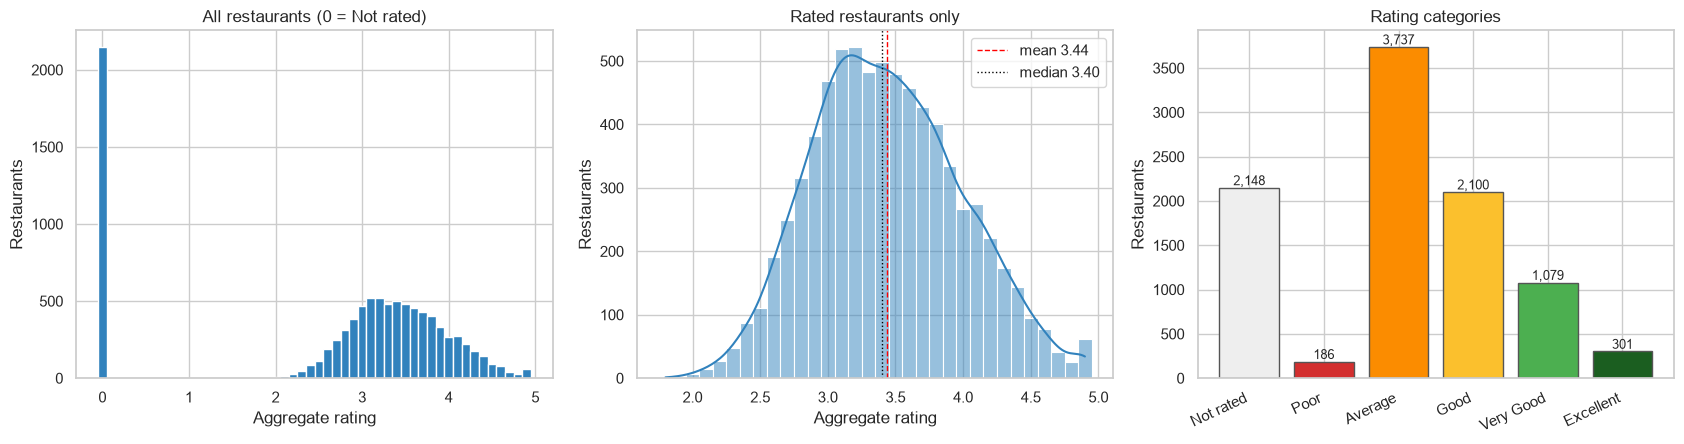

In [3]:
hex_colors = {"Dark Green": "#1b5e20", "Green": "#4caf50", "Yellow": "#fbc02d",
              "Orange": "#fb8c00", "Red": "#d32f2f", "White": "#eeeeee"}
order = ["Not rated", "Poor", "Average", "Good", "Very Good", "Excellent"]
counts = df["Rating text"].value_counts().reindex(order)
colour_for = df.groupby("Rating text")["Rating color"].first().reindex(order).map(hex_colors)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].hist(df[TARGET], bins=np.arange(-0.05, 5.0, 0.1), color=BLUE, edgecolor="white")
axes[0].set(title="All restaurants (0 = Not rated)", xlabel=TARGET, ylabel="Restaurants")

sns.histplot(rated[TARGET], bins=np.arange(1.75, 4.96, 0.1), kde=True, color=BLUE, ax=axes[1])
axes[1].axvline(rated[TARGET].mean(), color="red", ls="--", lw=1, label=f"mean {rated[TARGET].mean():.2f}")
axes[1].axvline(rated[TARGET].median(), color="black", ls=":", lw=1, label=f"median {rated[TARGET].median():.2f}")
axes[1].set(title="Rated restaurants only", xlabel=TARGET, ylabel="Restaurants")
axes[1].legend()

axes[2].bar(counts.index, counts.values, color=colour_for.values, edgecolor="#555")
for i, v in enumerate(counts.values):
    axes[2].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[2].set(title="Rating categories", xlabel="", ylabel="Restaurants")
plt.setp(axes[2].get_xticklabels(), rotation=25, ha="right")
plt.tight_layout()
plt.show()

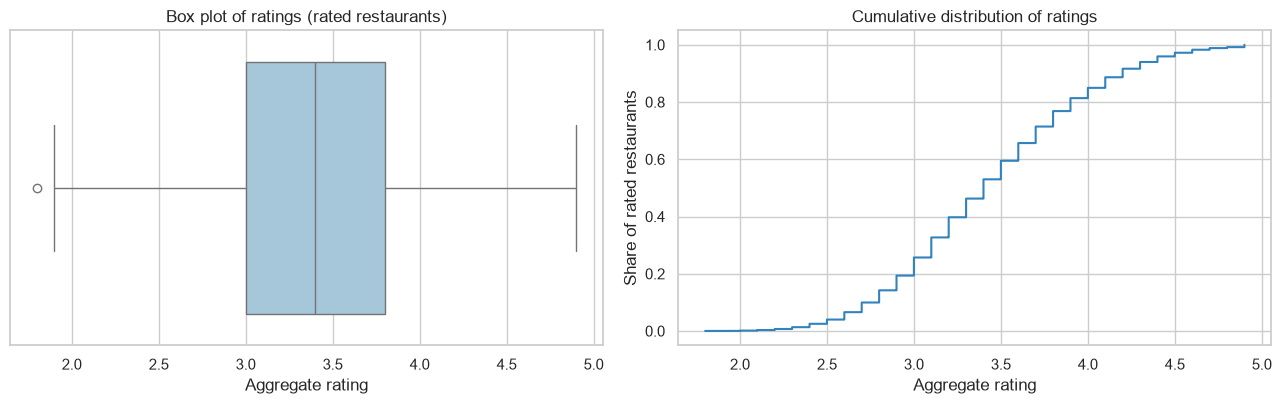

count   7,403.000
mean        3.440
std         0.552
min         1.800
25%         3.000
50%         3.400
75%         3.800
max         4.900


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(x=rated[TARGET], color="#9ecae1", ax=axes[0])
axes[0].set(title="Box plot of ratings (rated restaurants)", xlabel=TARGET)

xs = np.sort(rated[TARGET].to_numpy())
axes[1].step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", color=BLUE)
axes[1].set(title="Cumulative distribution of ratings", xlabel=TARGET, ylabel="Share of rated restaurants")
plt.tight_layout()
plt.show()
print(rated[TARGET].describe().round(3).to_string())

## 3. Average ratings: countries, cuisines, cities

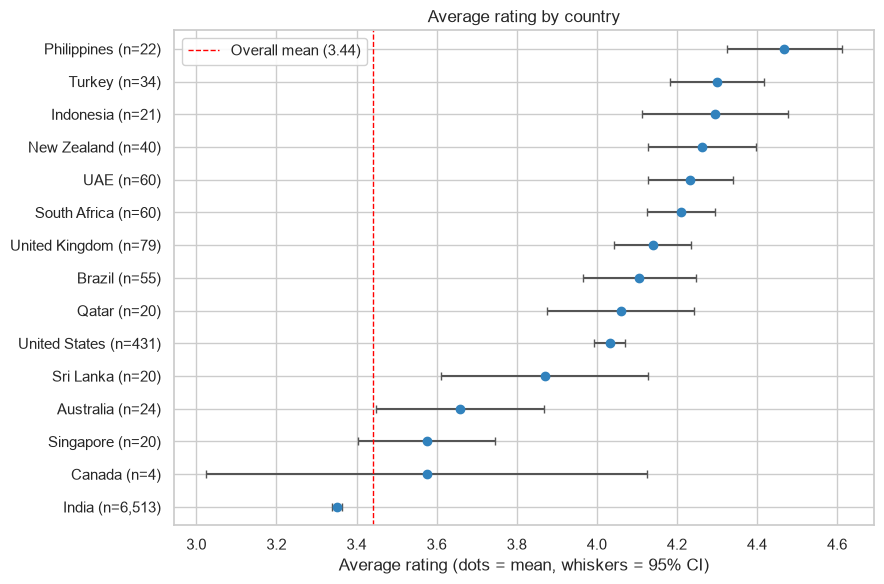

In [5]:
country_stats = mean_ci(rated, "Country")
country_stats.index = [f"{c} (n={int(n):,})" for c, n in zip(country_stats.index, country_stats["count"])]
fig, ax = plt.subplots(figsize=(9, 6))
barh_ci(ax, country_stats, "Average rating by country", ref=overall_mean)
plt.tight_layout()
plt.show()

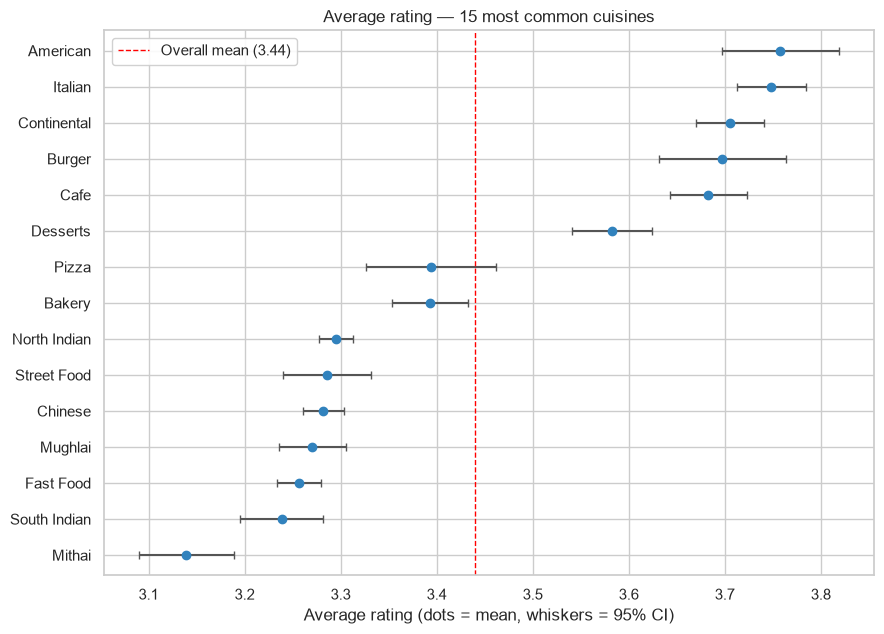

In [6]:
top_cuisines = cuisine_long["Cuisine"].value_counts().head(TOP_N).index
cuisine_stats = mean_ci(cuisine_long[cuisine_long["Cuisine"].isin(top_cuisines)], "Cuisine")
fig, ax = plt.subplots(figsize=(9, 6.5))
barh_ci(ax, cuisine_stats, f"Average rating — {TOP_N} most common cuisines", ref=overall_mean)
plt.tight_layout()
plt.show()

4 cities have >= 100 rated restaurants.
71 cities have >= 20 rated restaurants.


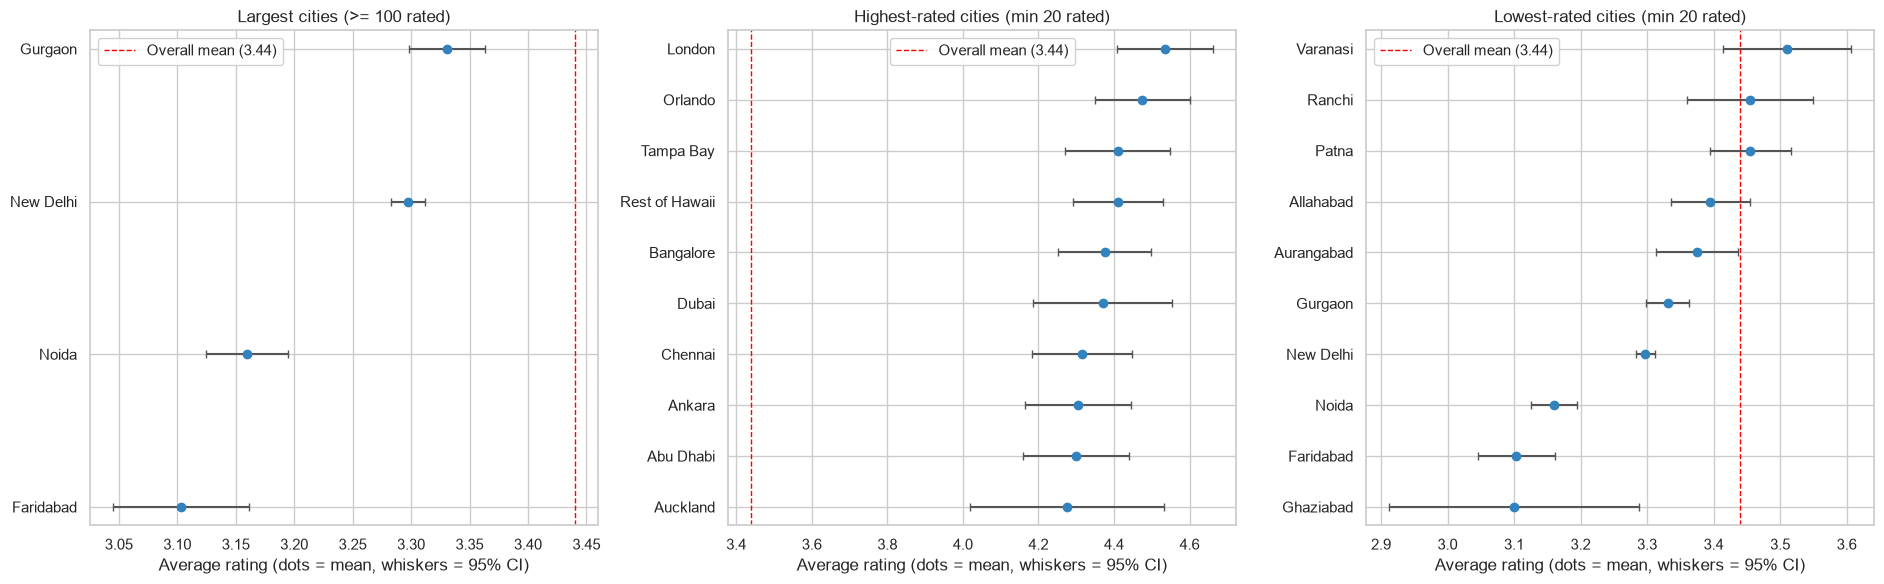

In [7]:
# Most cities in the data have only ~20 restaurants, so "top N by count" would be an arbitrary tie.
# Large cities are therefore defined by a count threshold instead.
city_large = mean_ci(rated, "City", min_n=LARGE_CITY_N)
print(f"{len(city_large)} cities have >= {LARGE_CITY_N} rated restaurants.")

city_all = mean_ci(rated, "City", min_n=MIN_CITY_N)
print(f"{len(city_all)} cities have >= {MIN_CITY_N} rated restaurants.")
best_cities = city_all.sort_values("mean", ascending=False).head(10)
worst_cities = city_all.sort_values("mean").head(10)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
barh_ci(axes[0], city_large, f"Largest cities (>= {LARGE_CITY_N} rated)", ref=overall_mean)
barh_ci(axes[1], best_cities, f"Highest-rated cities (min {MIN_CITY_N} rated)", ref=overall_mean)
barh_ci(axes[2], worst_cities, f"Lowest-rated cities (min {MIN_CITY_N} rated)", ref=overall_mean)
plt.tight_layout()
plt.show()

## 4. Relationships between features and the rating

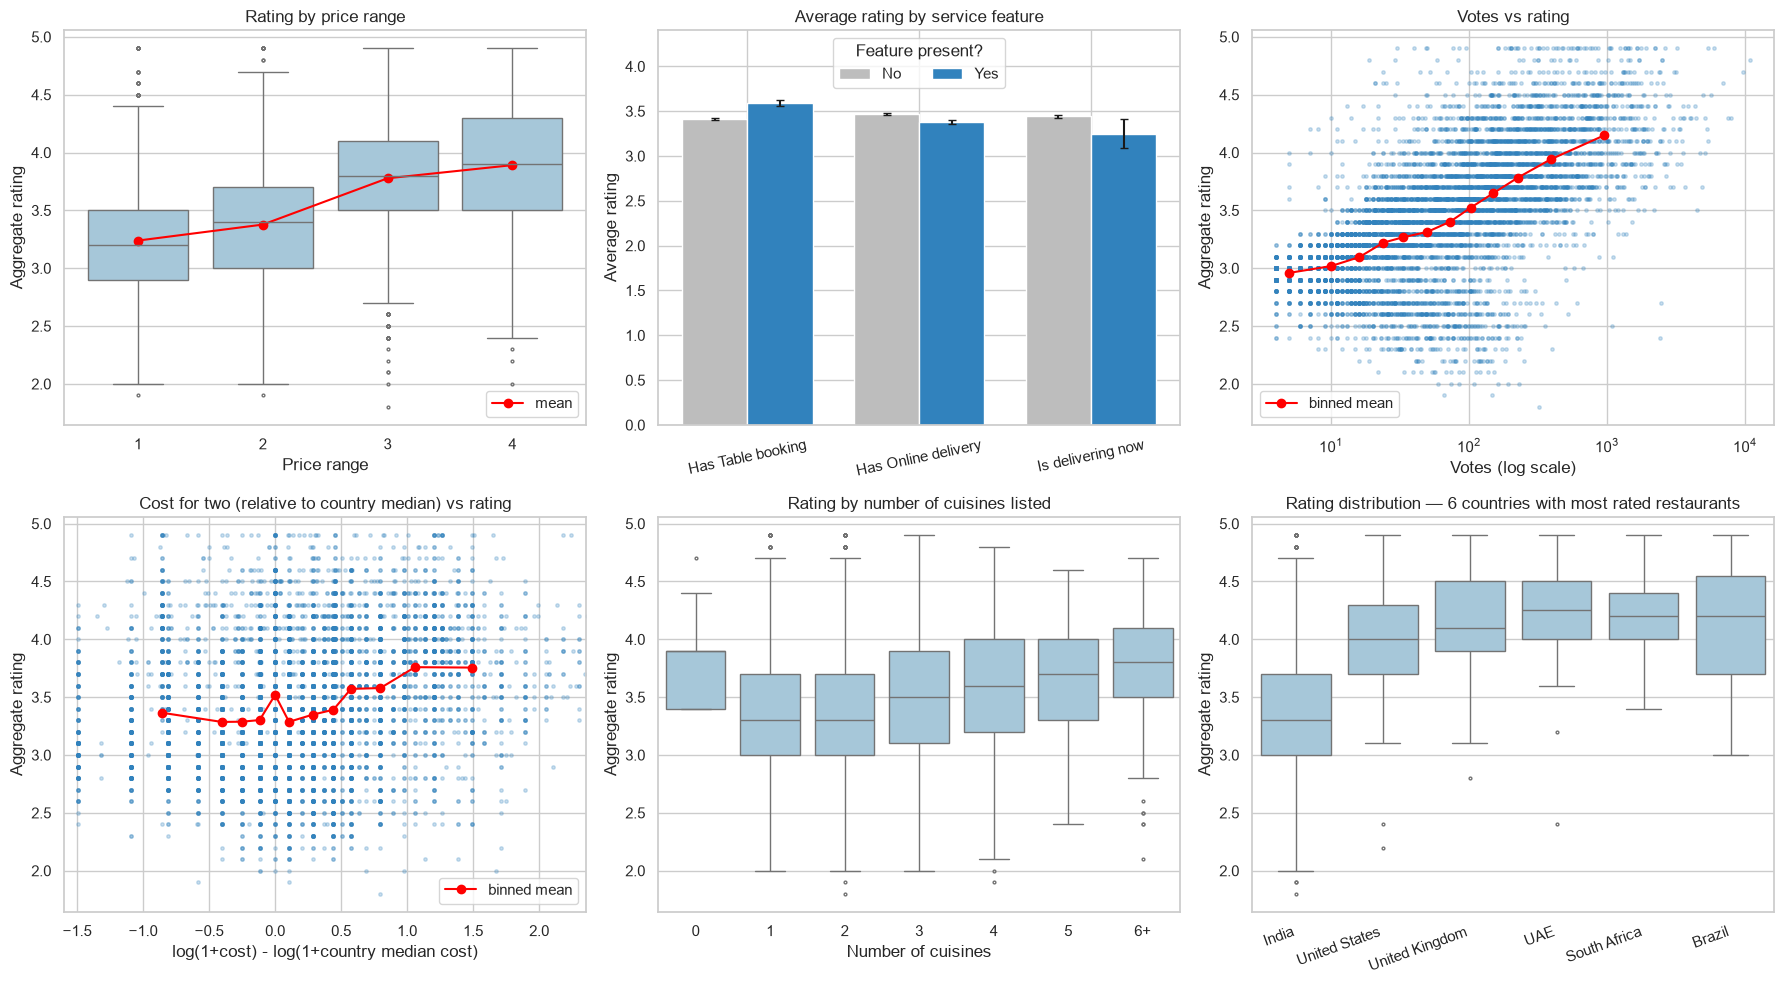

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# (a) Price range
sns.boxplot(data=rated, x="Price range", y=TARGET, color="#9ecae1", fliersize=2, ax=axes[0, 0])
means = rated.groupby("Price range")[TARGET].mean()
axes[0, 0].plot(range(len(means)), means.values, "o-", color="red", label="mean")
axes[0, 0].set(title="Rating by price range")
axes[0, 0].legend()

# (b) Binary service features
flags = ["Has Table booking", "Has Online delivery", "Is delivering now"]
ax = axes[0, 1]
for j, val in enumerate(["No", "Yes"]):
    m, e = [], []
    for f in flags:
        s = rated.loc[rated[f] == val, TARGET]
        m.append(s.mean())
        e.append(1.96 * s.std() / np.sqrt(len(s)))
    ax.bar(np.arange(3) + (j - 0.5) * 0.38, m, 0.38, yerr=e, capsize=3, label=val,
           color=["#bdbdbd", BLUE][j])
ax.set_xticks(range(3))
ax.set_xticklabels(flags, rotation=12)
ax.set(title="Average rating by service feature", ylabel="Average rating", ylim=(0, 4.4))
ax.legend(title="Feature present?", loc="upper center", ncol=2)

# (c) Votes
axes[0, 2].scatter(rated["Votes"], rated[TARGET], s=6, alpha=0.25, color=BLUE)
tr = binned_trend(rated["Votes"], rated[TARGET])
axes[0, 2].plot(tr["x"], tr["y"], "o-", color="red", label="binned mean")
axes[0, 2].set_xscale("log")
axes[0, 2].set(title="Votes vs rating", xlabel="Votes (log scale)", ylabel=TARGET)
axes[0, 2].legend()

# (d) Relative cost
axes[1, 0].scatter(rated["Relative Cost (log)"], rated[TARGET], s=6, alpha=0.25, color=BLUE)
tr = binned_trend(rated["Relative Cost (log)"], rated[TARGET])
axes[1, 0].plot(tr["x"], tr["y"], "o-", color="red", label="binned mean")
lo, hi = rated["Relative Cost (log)"].quantile([0.005, 0.995])
axes[1, 0].set_xlim(lo - 0.1, hi + 0.1)
axes[1, 0].set(title="Cost for two (relative to country median) vs rating",
               xlabel="log(1+cost) - log(1+country median cost)", ylabel=TARGET)
axes[1, 0].legend()

# (e) Number of cuisines
rated_nc = rated.assign(**{"Num Cuisines (capped)": rated["Num Cuisines"].clip(upper=6).astype(int).astype(str).replace("6", "6+")})
nc_order = sorted(rated_nc["Num Cuisines (capped)"].unique(), key=lambda v: int(v.replace("+", "")))
sns.boxplot(data=rated_nc, x="Num Cuisines (capped)", y=TARGET, order=nc_order, color="#9ecae1", fliersize=2, ax=axes[1, 1])
axes[1, 1].set(title="Rating by number of cuisines listed", xlabel="Number of cuisines")

# (f) Top countries' rating distributions
top_countries = rated["Country"].value_counts().head(6).index
sns.boxplot(data=rated[rated["Country"].isin(top_countries)], x="Country", y=TARGET, order=list(top_countries),
            color="#9ecae1", fliersize=2, ax=axes[1, 2])
axes[1, 2].set(title="Rating distribution — 6 countries with most rated restaurants", xlabel="")
plt.setp(axes[1, 2].get_xticklabels(), rotation=20, ha="right")

plt.tight_layout()
plt.show()

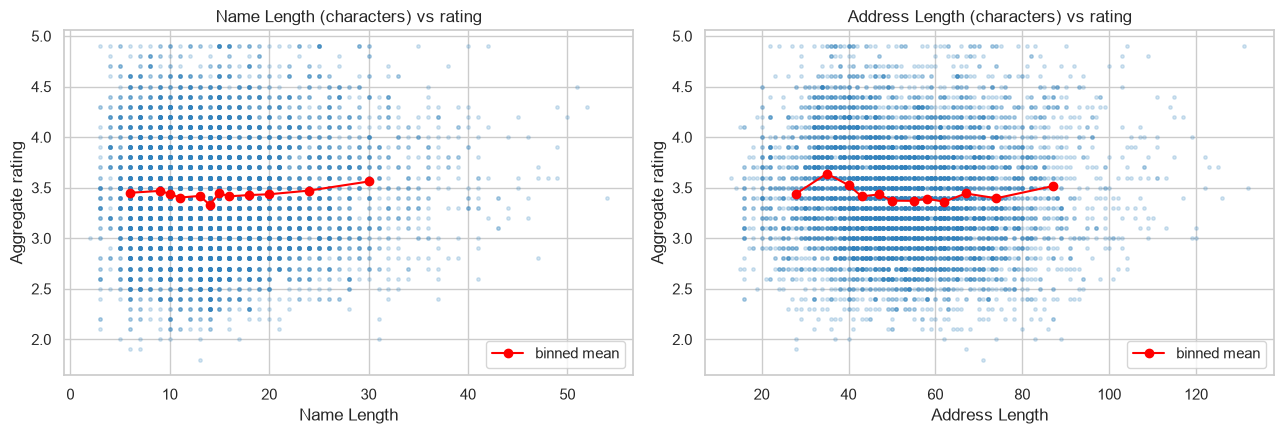

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["Name Length", "Address Length"]):
    ax.scatter(rated[col], rated[TARGET], s=6, alpha=0.2, color=BLUE)
    tr = binned_trend(rated[col], rated[TARGET])
    ax.plot(tr["x"], tr["y"], "o-", color="red", label="binned mean")
    ax.set(title=f"{col} (characters) vs rating", xlabel=col, ylabel=TARGET)
    ax.legend()
plt.tight_layout()
plt.show()

### Geographic view
Restaurants with a zero (placeholder) longitude or latitude are excluded. The right panel zooms into the country with the
most restaurants (central 98% of its coordinates).

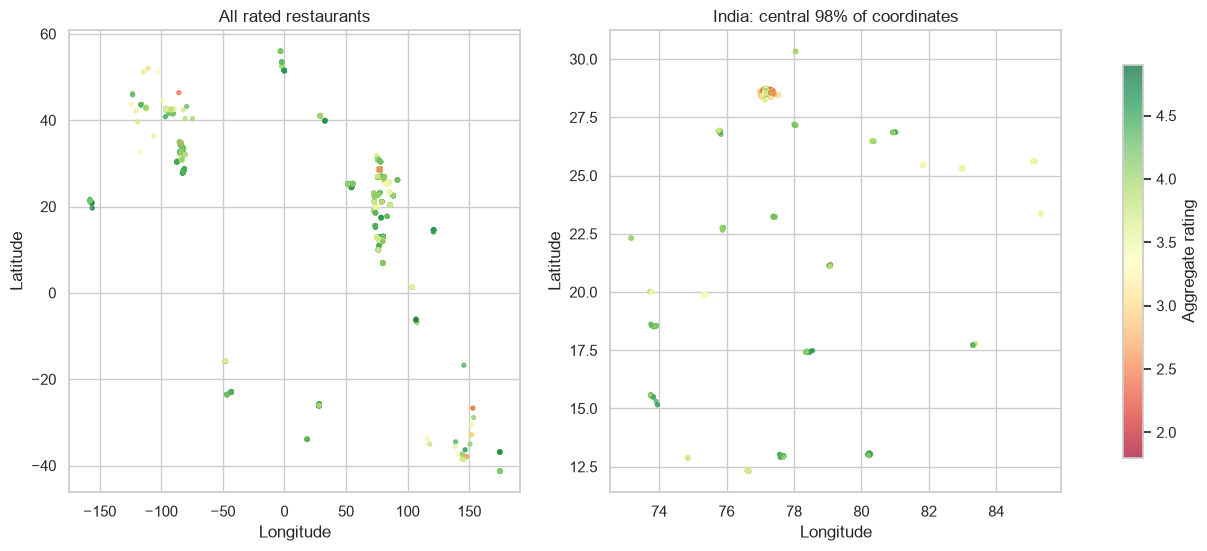

In [10]:
geo = rated[valid_geo.loc[rated.index]]
main_country = geo["Country"].value_counts().index[0]
g_main = geo[geo["Country"] == main_country]
lon_lo, lon_hi = g_main["Longitude"].quantile([0.01, 0.99])
lat_lo, lat_hi = g_main["Latitude"].quantile([0.01, 0.99])
zoom = g_main[g_main["Longitude"].between(lon_lo, lon_hi) & g_main["Latitude"].between(lat_lo, lat_hi)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sc = axes[0].scatter(geo["Longitude"], geo["Latitude"], c=geo[TARGET], cmap="RdYlGn", s=8, alpha=0.7)
axes[0].set(title="All rated restaurants", xlabel="Longitude", ylabel="Latitude")
sc2 = axes[1].scatter(zoom["Longitude"], zoom["Latitude"], c=zoom[TARGET], cmap="RdYlGn", s=8, alpha=0.7)
axes[1].set(title=f"{main_country}: central 98% of coordinates", xlabel="Longitude", ylabel="Latitude")
fig.colorbar(sc2, ax=axes, label=TARGET, shrink=0.85)
plt.show()

### Correlation overview
Spearman rank correlation is used because votes and costs are heavily skewed and several variables are ordinal/binary.

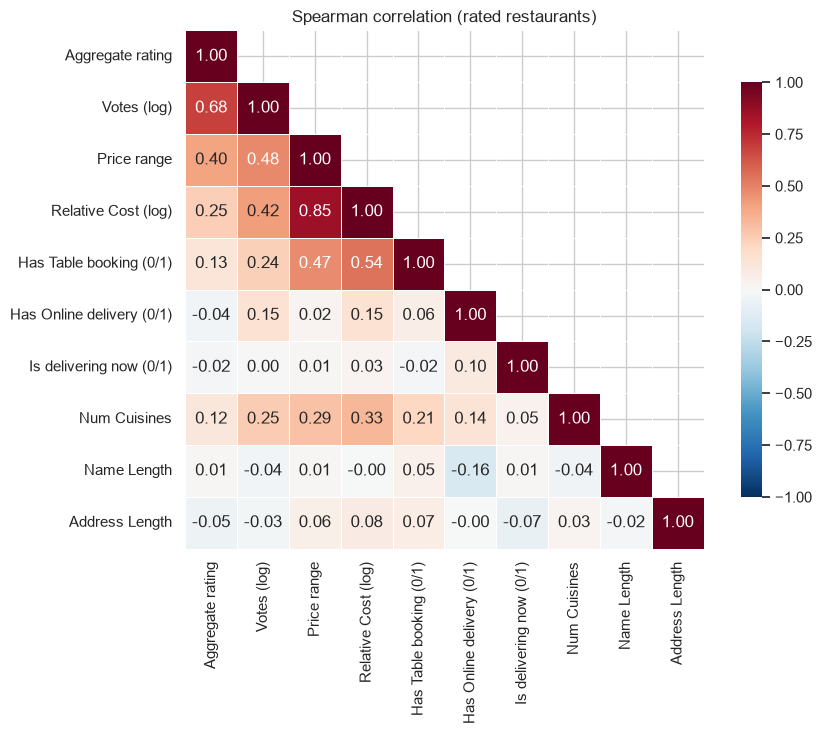

In [11]:
corr_cols = [TARGET, "Votes (log)", "Price range", "Relative Cost (log)", "Has Table booking (0/1)",
             "Has Online delivery (0/1)", "Is delivering now (0/1)", "Num Cuisines", "Name Length", "Address Length"]
corr = rated[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9.5, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set(title="Spearman correlation (rated restaurants)")
plt.tight_layout()
plt.show()

## 5. Summary

In [12]:
target_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print("Features ranked by |Spearman correlation| with rating:")
print(target_corr.round(3).to_string())

best_c = cuisine_stats["mean"].idxmax()
worst_c = cuisine_stats["mean"].idxmin()
print(f"\nAmong the {TOP_N} most common cuisines: highest average = {best_c} ({cuisine_stats.loc[best_c, 'mean']:.2f}), "
      f"lowest = {worst_c} ({cuisine_stats.loc[worst_c, 'mean']:.2f})")
print(f"Highest-rated city (min {MIN_CITY_N} rated): {city_all['mean'].idxmax()} ({city_all['mean'].max():.2f}); "
      f"lowest: {city_all['mean'].idxmin()} ({city_all['mean'].min():.2f})")
print(f"Overall mean rating of rated restaurants: {overall_mean:.2f}")

Features ranked by |Spearman correlation| with rating:
Votes (log)                  0.682
Price range                  0.402
Relative Cost (log)          0.247
Has Table booking (0/1)      0.126
Num Cuisines                 0.116
Address Length              -0.052
Has Online delivery (0/1)   -0.039
Is delivering now (0/1)     -0.021
Name Length                  0.012

Among the 15 most common cuisines: highest average = American (3.76), lowest = Mithai (3.14)
Highest-rated city (min 20 rated): London (4.54); lowest: Ghaziabad (3.10)
Overall mean rating of rated restaurants: 3.44


**Notes**
- Correlations and group differences are associations, not causal effects.
- Rankings of small groups are noisy; confidence intervals and minimum sample sizes are shown to indicate this.
- `Votes` is recorded after ratings accumulate, so its relationship with rating is not a pre-launch signal.